# CG-FASFF — Improving GAF-Net on Corn-Leaf-Disease-17

Ablation against the **YOLOv8n baseline**, same dataset, same training recipe.

| Run | Neck conv | P3 block | Fusion | Status |
|---|---|---|---|---|
| **A** YOLOv8n | — | — | — | **reuse** uploaded `best.pt` |
| **B** GAF-Net | `GSConv` (1x1 s2) | `GSConv` | `FASFF` | retrain here |
| **C** +fixes | `GSConvX` (kxk s2) | `C2f` | `FASFF` | train here |
| **D** +CG-FASFF | `GSConvX` | `C2f` | `CGFASFF` | train here — **Ours** |

Run A's checkpoint was trained with `optimizer: auto`, so every run below uses the
**same** recipe (auto optimizer, ultralytics defaults) and the comparison is controlled.
3 runs, roughly 2h15m on one T4.

Target metric: **mAP50-95** and **per-class AP50 on `gray_spot`** (mAP50 is saturated ~98% on this dataset).

## 0 — Config

In [1]:
import os, shutil, json
from pathlib import Path

SAVE_DIR = Path("/kaggle/working/saved_checkpoints"); SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ── Run A: your previously trained YOLOv8n baseline ──────────────────────────
# Upload best.pt.zip as a Kaggle Dataset, then Add Input -> Datasets -> it.
# Kaggle auto-extracts the zip, so the file lands directly in the mount folder.
BASELINE_PT = Path("/kaggle/input/corn-baseline/best.pt")   # <-- EDIT THIS PATH

# ── Training recipe — matched to run A (which used optimizer="auto") ─────────
# Do not add lr0 / optimizer here: run A used ultralytics defaults, and every
# run must match it for the ablation to be valid.
TRAIN_CFG = dict(
    epochs=100, imgsz=640, batch=16,
    seed=0, deterministic=True,
    device=0,            # single GPU on purpose - DDP would change effective
                         # batch size and BatchNorm stats across runs
    save=True, plots=True, val=True,
)

print("Run A checkpoint:", BASELINE_PT)
print("  ->", "FOUND" if BASELINE_PT.exists() else "MISSING  <-- fix the path above")
if not BASELINE_PT.exists():
    print("\n  Contents of /kaggle/input:")
    for p in sorted(Path("/kaggle/input").rglob("*"))[:40]:
        print("   ", p)

Run A checkpoint: /kaggle/input/corn-baseline/best.pt
  -> MISSING  <-- fix the path above

  Contents of /kaggle/input:
    /kaggle/input/datasets
    /kaggle/input/datasets/manideepmaram
    /kaggle/input/datasets/manideepmaram/corn-baseline
    /kaggle/input/datasets/manideepmaram/corn-baseline/best
    /kaggle/input/datasets/manideepmaram/corn-baseline/best/.data
    /kaggle/input/datasets/manideepmaram/corn-baseline/best/.data/serialization_id
    /kaggle/input/datasets/manideepmaram/corn-baseline/best/.format_version
    /kaggle/input/datasets/manideepmaram/corn-baseline/best/.storage_alignment
    /kaggle/input/datasets/manideepmaram/corn-baseline/best/byteorder
    /kaggle/input/datasets/manideepmaram/corn-baseline/best/data
    /kaggle/input/datasets/manideepmaram/corn-baseline/best/data/0
    /kaggle/input/datasets/manideepmaram/corn-baseline/best/data/1
    /kaggle/input/datasets/manideepmaram/corn-baseline/best/data/10
    /kaggle/input/datasets/manideepmaram/corn-baseline/

## 1 — Install + dataset (Corn-Leaf-Disease-17)

In [2]:
!pip -q install roboflow ultralytics

from roboflow import Roboflow
rf = Roboflow(api_key="E5GHF0z58MbGLONGk5VF")
project = rf.workspace("aziz-jda2k").project("corn-leaf-disease-hgosu")
dataset = project.version(17).download("yolov8")

DATA = f"{dataset.location}/data.yaml"
print("DATA =", DATA)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Corn-Leaf-Disease-17 in yolov8:: 100%|██████████| 21754/21754 [00:02<00:00, 9966.80it/s] 


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
DATA = /kaggle/working/Corn-Leaf-Disease-17/data.yaml


In [3]:
import zipfile
from pathlib import Path

EXPLODED    = Path("/kaggle/input/datasets/manideepmaram/corn-baseline/best")
BASELINE_PT = Path("/kaggle/working/baseline_best.pt")

# Kaggle unpacked best.pt (torch checkpoints are zip archives). Repack it.
if not BASELINE_PT.exists():
    with zipfile.ZipFile(BASELINE_PT, "w", zipfile.ZIP_STORED) as z:
        for f in sorted(EXPLODED.rglob("*")):
            if f.is_file():
                zi = zipfile.ZipInfo(str(Path("best") / f.relative_to(EXPLODED)),
                                     date_time=(1980, 1, 1, 0, 0, 0))
                z.writestr(zi, f.read_bytes())
print(f"rebuilt -> {BASELINE_PT}  ({BASELINE_PT.stat().st_size/1e6:.2f} MB)")

from ultralytics import YOLO
_m = YOLO(str(BASELINE_PT))
print("names :", _m.model.names)
print("params:", f"{sum(p.numel() for p in _m.model.parameters()):,}")
del _m

rebuilt -> /kaggle/working/baseline_best.pt  (6.25 MB)
names : {0: 'blight', 1: 'common_rust', 2: 'gray_spot', 3: 'health'}
params: 3,011,628


## 2 — Modules

`GSConv` / `FASFF` are kept **byte-identical to the previous notebook** so run B's
checkpoint unpickles correctly. The new work is `GSConvX` and `CGFASFF`.

In [4]:
import torch, torch.nn as nn, torch.nn.functional as F
from ultralytics.nn import tasks
from copy import deepcopy


class GSConv(nn.Module):
    """Original GAF-Net GSConv (run B). Downsamples with a 1x1 stride-s conv."""
    def __init__(self, c1, c2=None, k=3, s=1):
        super().__init__()
        if c2 is None:
            c2 = c1
        c_ = c2 // 2
        self.cv1 = nn.Conv2d(c1, c_, 1, s)
        self.dw  = nn.Conv2d(c_, c_, k, 1, padding=k // 2, groups=c_)
        self.bn  = nn.BatchNorm2d(c_)
        self.act = nn.SiLU()

    def forward(self, x):
        x1 = self.cv1(x)
        x2 = self.act(self.bn(self.dw(x1)))
        y = torch.cat((x1, x2), dim=1)
        b, c, h, w = y.shape
        return y.reshape(b, 2, c // 2, h, w).permute(0, 2, 1, 3, 4).reshape(b, c, h, w)


class GSConvX(nn.Module):
    """GSConv with a kxk strided convolution instead of 1x1.

    The 1x1 stride-2 conv in the original samples one pixel in four with no
    spatial support, destroying exactly the fine texture that `gray_spot`
    depends on. A kxk strided conv keeps that information at ~15k extra params.
    """
    def __init__(self, c1, c2=None, k=3, s=1):
        super().__init__()
        if c2 is None:
            c2 = c1
        c_ = c2 // 2
        self.cv1  = nn.Conv2d(c1, c_, k, s, padding=k // 2, bias=False)
        self.bn1  = nn.BatchNorm2d(c_)
        self.act1 = nn.SiLU()
        self.dw   = nn.Conv2d(c_, c_, k, 1, padding=k // 2, groups=c_, bias=False)
        self.bn   = nn.BatchNorm2d(c_)
        self.act  = nn.SiLU()

    def forward(self, x):
        x1 = self.act1(self.bn1(self.cv1(x)))
        x2 = self.act(self.bn(self.dw(x1)))
        y = torch.cat((x1, x2), dim=1)
        b, c, h, w = y.shape
        return y.reshape(b, 2, c // 2, h, w).permute(0, 2, 1, 3, 4).reshape(b, c, h, w)


def _resize_to(x, size):
    if x.shape[-2:] == size:
        return x
    if x.shape[-2] > size[0] or x.shape[-1] > size[1]:
        return F.adaptive_avg_pool2d(x, size)
    return F.interpolate(x, size=size, mode="nearest")


class FASFF(nn.Module):
    """Original FASFF (runs B, C). One weight map per level, computed in isolation."""
    def __init__(self, c1, c2=256, level=0):
        super().__init__()
        if isinstance(c1, int):
            c1 = [c1, c1, c1]
        self.level = level
        self.c2 = c2
        self.reduce = nn.ModuleList([
            nn.Sequential(nn.Conv2d(ci, c2, 1, 1, bias=False),
                          nn.BatchNorm2d(c2), nn.SiLU()) for ci in c1
        ])
        self.weight_layers = nn.ModuleList([nn.Conv2d(c2, 1, 1, 1, 0) for _ in range(3)])

    def _resize_to(self, x, size):
        return _resize_to(x, size)

    def forward(self, x):
        t = x[self.level].shape[-2:]
        f = [self.reduce[i](_resize_to(x[i], t)) for i in range(3)]
        w = torch.softmax(torch.stack([self.weight_layers[i](f[i]) for i in range(3)], 0), 0)
        return w[0] * f[0] + w[1] * f[1] + w[2] * f[2]


class CGFASFF(nn.Module):
    """Cross-level Gated, channel-Grouped Adaptive Spatial Feature Fusion.

    Two changes over FASFF:
      1. CROSS-LEVEL  - the gate sees all three levels concatenated, so each
         scale's weight is decided with knowledge of the others, instead of
         each level scoring itself blindly before a softmax arbitrates.
      2. CHANNEL-GROUPED - emits `groups` weights per level instead of one,
         so different channel groups can draw from different scales at the
         same pixel (texture from P3, colour from P5).

    Cost: one 1x1 bottleneck per instance, ~7k params.
    """
    def __init__(self, c1, c2=256, level=0, groups=8):
        super().__init__()
        if isinstance(c1, int):
            c1 = [c1, c1, c1]
        while groups > 1 and c2 % groups:
            groups //= 2
        self.level, self.c2, self.g = level, c2, max(groups, 1)
        self.reduce = nn.ModuleList([
            nn.Sequential(nn.Conv2d(ci, c2, 1, 1, bias=False),
                          nn.BatchNorm2d(c2), nn.SiLU()) for ci in c1
        ])
        h = max(c2 // 2, 16)
        self.gate = nn.Sequential(
            nn.Conv2d(3 * c2, h, 1, bias=False), nn.BatchNorm2d(h), nn.SiLU(),
            nn.Conv2d(h, 3 * self.g, 1),
        )

    def forward(self, x):
        t = x[self.level].shape[-2:]
        f = [self.reduce[i](_resize_to(x[i], t)) for i in range(3)]
        w = self.gate(torch.cat(f, dim=1))                    # B, 3G, H, W
        B, _, H, W = w.shape
        w = w.view(B, 3, self.g, H, W).softmax(dim=1)         # softmax ACROSS levels
        w = w.repeat_interleave(self.c2 // self.g, dim=2)     # group -> channel
        return (w * torch.stack(f, dim=1)).sum(dim=1)


_GS     = {"GSConv": GSConv, "GSConvX": GSConvX}
_FUSION = {"FASFF": FASFF, "CGFASFF": CGFASFF}
for _k, _v in {**_GS, **_FUSION}.items():
    setattr(tasks, _k, _v)
print("modules defined:", list(_GS) + list(_FUSION))

modules defined: ['GSConv', 'GSConvX', 'FASFF', 'CGFASFF']


## 3 — `parse_model` patch (handles both GSConv and both fusion variants)

In [5]:
def _get_out_channels(m):
    if isinstance(m, (GSConv, GSConvX)):
        return m.cv1.out_channels * 2
    if isinstance(m, (FASFF, CGFASFF)):
        return m.c2
    if isinstance(m, nn.Sequential) and len(m) > 0:
        return _get_out_channels(m[-1])
    if hasattr(m, "cv2"):
        return _get_out_channels(m.cv2)
    if hasattr(m, "conv") and isinstance(m.conv, nn.Conv2d):
        return m.conv.out_channels
    for child in reversed(list(m.children())):
        r = _get_out_channels(child)
        if r is not None:
            return r
    return None


if not hasattr(tasks, "_original_parse_model"):
    tasks._original_parse_model = tasks.parse_model


def patched_parse_model(d, ch, verbose=True):
    d2 = deepcopy(d)
    fus, gs = [], []
    for sec in ("backbone", "head"):
        for i, layer in enumerate(d2.get(sec, [])):
            f, n, name, args = layer
            if name in _FUSION:
                fus.append((sec, i, f, args, name))
                d2[sec][i] = [-1, 1, "Conv", [args[0], 1, 1]]
            elif name in _GS:
                gs.append((sec, i, f, args, name))
                d2[sec][i] = [f, n, "Conv", args]

    model, save = tasks._original_parse_model(d2, ch, verbose)
    if not gs and not fus:
        return model, save

    bl = len(d.get("backbone", []))

    for sec, idx, fv, a, name in gs:
        gi = idx if sec == "backbone" else bl + idx
        dm = model[gi]
        cm = dm[0] if isinstance(dm, nn.Sequential) else dm
        c1, c2 = cm.conv.in_channels, cm.conv.out_channels
        k = a[1] if len(a) > 1 else 3
        s = a[2] if len(a) > 2 else 1
        na = len(dm) if isinstance(dm, nn.Sequential) else 1
        C = _GS[name]
        if na > 1:
            new = nn.Sequential(*(C(c1 if j == 0 else c2, c2, k, s if j == 0 else 1)
                                  for j in range(na)))
        else:
            new = C(c1, c2, k, s)
        new.i, new.f, new.type = gi, fv, name
        new.np = sum(p.numel() for p in new.parameters())
        model[gi] = new

    for sec, idx, fv, a, name in fus:
        gi = idx if sec == "backbone" else bl + idx
        if isinstance(fv, list):
            ics = [_get_out_channels(model[x]) for x in fv]
        else:
            ics = [_get_out_channels(model[fv])] * 3
        c2 = _get_out_channels(model[gi])
        level = a[1] if len(a) > 1 else 0
        mod = _FUSION[name](ics, c2, level)
        mod.i, mod.f, mod.type = gi, fv, name
        mod.np = sum(p.numel() for p in mod.parameters())
        model[gi] = mod
        if isinstance(fv, list):
            for x in fv:
                r = x if x >= 0 else gi + x
                if r not in save:
                    save.append(r)

    return model, save


tasks.parse_model = patched_parse_model
print("parse_model patched")

parse_model patched


## 4 — Architecture YAML builder

In [6]:
def write_yaml(path, gs="GSConv", p3="GSConv", fusion="FASFF", nc=4):
    """Layer indices stay fixed at 15 / 18 / 21 so the fusion inputs never move."""
    Path(path).write_text(f"""
nc: {nc}
scales:
  n: [0.33, 0.25, 1024]

backbone:
  - [-1, 1, Conv, [64, 3, 2]]
  - [-1, 1, Conv, [128, 3, 2]]
  - [-1, 3, C2f, [128, True]]
  - [-1, 1, Conv, [256, 3, 2]]
  - [-1, 6, C2f, [256, True]]
  - [-1, 1, Conv, [512, 3, 2]]
  - [-1, 6, C2f, [512, True]]
  - [-1, 1, Conv, [1024, 3, 2]]
  - [-1, 3, C2f, [1024, True]]
  - [-1, 1, SPPF, [1024, 5]]

head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 6], 1, Concat, [1]]
  - [-1, 3, {gs}, [512]]

  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 4], 1, Concat, [1]]
  - [-1, 3, {p3}, [256]]

  - [-1, 1, {gs}, [256, 3, 2]]
  - [[-1, 12], 1, Concat, [1]]
  - [-1, 3, {gs}, [512]]

  - [-1, 1, {gs}, [512, 3, 2]]
  - [[-1, 9], 1, Concat, [1]]
  - [-1, 3, {gs}, [1024]]

  - [[15, 18, 21], 1, {fusion}, [256, 0]]
  - [[15, 18, 21], 1, {fusion}, [256, 1]]
  - [[15, 18, 21], 1, {fusion}, [256, 2]]

  - [[22, 23, 24], 1, Detect, [nc]]
""")
    return path


YAML_B = write_yaml("/kaggle/working/arch_B.yaml", gs="GSConv",  p3="GSConv", fusion="FASFF")
YAML_C = write_yaml("/kaggle/working/arch_C.yaml", gs="GSConvX", p3="C2f",    fusion="FASFF")
YAML_D = write_yaml("/kaggle/working/arch_D.yaml", gs="GSConvX", p3="C2f",    fusion="CGFASFF")

# sanity check: build all three and print size before committing to ~2h of training
from ultralytics import YOLO
for tag, y in [("B", YAML_B), ("C", YAML_C), ("D", YAML_D)]:
    m = YOLO(y)
    n = sum(p.numel() for p in m.model.parameters())
    print(f"{tag}: {n/1e6:.3f} M params")
    del m

WARNING ⚠️ no model scale passed. Assuming scale='n'.
B: 1.925 M params
WARNING ⚠️ no model scale passed. Assuming scale='n'.
C: 2.726 M params
WARNING ⚠️ no model scale passed. Assuming scale='n'.
D: 2.746 M params


## 5 — Train (resume-safe: re-running skips finished runs)

In [7]:
from ultralytics import YOLO

def train_if_needed(name, src, load_pretrained=True):
    out = Path(f"/kaggle/working/runs/detect/{name}/weights/best.pt")
    if out.exists():
        print(f"[skip] {name} already trained -> {out}")
        return str(out)
    print(f"\n{'='*70}\n  TRAINING {name}\n{'='*70}")
    m = YOLO(src)
    if load_pretrained and str(src).endswith(".yaml"):
        m.load("yolov8n.pt")
    m.train(data=DATA, name=name, **TRAIN_CFG)
    dst = SAVE_DIR / name
    dst.mkdir(parents=True, exist_ok=True)
    for w in out.parent.glob("*.pt"):
        shutil.copy(w, dst / w.name)
    for extra in ("results.csv", "args.yaml"):
        p = out.parent.parent / extra
        if p.exists():
            shutil.copy(p, dst / extra)
    print(f"[saved] {dst}")
    return str(out)


PATHS = {}
PATHS["A_YOLOv8n"]      = str(BASELINE_PT)                      # reused, not retrained
PATHS["B_GAF-Net"]      = train_if_needed("B_gafnet",   YAML_B)
PATHS["C_+GSConvX+C2f"] = train_if_needed("C_fixed",    YAML_C)
PATHS["D_+CG-FASFF"]    = train_if_needed("D_cgfasff",  YAML_D)

print("\n" + json.dumps(PATHS, indent=2))


  TRAINING B_gafnet
WARNING ⚠️ no model scale passed. Assuming scale='n'.
Transferred 164/373 items from pretrained weights
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Corn-Leaf-Disease-17/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0

adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)


      1/100      2.01G      1.683      2.181      2.864          9        640: 100% ━━━━━━━━━━━━ 628/628 5.8it/s 1:49
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 1.9it/s 7.2s
                   all        419        420      0.543      0.844      0.734      0.605

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      2/100      2.61G     0.8405      1.073      1.795         48        640: 0% ──────────── 0/628  0.2s

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)


      2/100      2.61G     0.6672      1.019      1.428          8        640: 100% ━━━━━━━━━━━━ 628/628 7.1it/s 1:29
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 6.2it/s 2.2s
                   all        419        420      0.808      0.787      0.862      0.735

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100      2.61G     0.5838     0.8793      1.285         49        640: 0% ──────────── 1/628 2.5it/s 0.3s<4:16

...

     98/100      3.11G     0.1762     0.1349       1.04          3        640: 100% ━━━━━━━━━━━━ 628/628 6.8it/s 1:33
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 6.0it/s 2.3s
                   all        419        420      0.941       0.96      0.978      0.905

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
     99/100      3.11G     0.1245    0.09488     0.9478         16        640: 0% ──────────── 0/628  0.2s

adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)


     99/100      3.11G     0.1767     0.1341      1.038          3        640: 100% ━━━━━━━━━━━━ 628/628 6.8it/s 1:33
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 6.2it/s 2.3s
                   all        419        420      0.935      0.961      0.977      0.904

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
    100/100      3.11G     0.2241     0.1297      1.043         16        640: 0% ──────────── 1/628 2.4it/s 0.3s<4:19

adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)


    100/100      3.11G     0.1763     0.1342      1.036          3        640: 100% ━━━━━━━━━━━━ 628/628 6.8it/s 1:33
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 6.1it/s 2.3s
                   all        419        420      0.934      0.961      0.977      0.905

100 epochs completed in 2.661 hours.
Optimizer stripped from /kaggle/working/runs/detect/D_cgfasff/weights/last.pt, 5.8MB
Optimizer stripped from /kaggle/working/runs/detect/D_cgfasff/weights/best.pt, 5.8MB

Validating /kaggle/working/runs/detect/D_cgfasff/weights/best.pt...
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
arch_D summary (fused): 127 layers, 2,742,660 parameters, 0 gradients, 8.3 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 4.2it/s 3.3s
                   all        419        420      0.967       0.92      0.977      0.911
       

## 6 — Evaluate all four on the **test** split

In [8]:
import pandas as pd
from ultralytics import YOLO

rows = []
for label, w in PATHS.items():
    if not Path(w).exists():
        print(f"[warn] missing, skipped: {label} -> {w}")
        continue
    mdl = YOLO(w)
    r = mdl.val(data=DATA, split="test", verbose=False)
    n_params = sum(p.numel() for p in mdl.model.parameters())
    try:
        flops = mdl.info(verbose=False)[3]
    except Exception:
        flops = float("nan")
    per_class = {f"AP50_{r.names[c]}": float(v)
                 for c, v in zip(r.box.ap_class_index, r.box.ap50)}
    rows.append({"Model": label,
                 "P": float(r.box.mp), "R": float(r.box.mr),
                 "mAP50": float(r.box.map50), "mAP50-95": float(r.box.map),
                 **per_class,
                 "Params(M)": n_params / 1e6, "GFLOPs": flops})

df = pd.DataFrame(rows).set_index("Model").round(4)
df.to_csv(SAVE_DIR / "ablation_results.csv")
print(df.to_string())

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1313.6±387.0 MB/s, size: 61.5 KB)
val: Scanning /kaggle/working/Corn-Leaf-Disease-17/test/labels... 417 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 417/417 1.2Kit/s 0.4s
val: New cache created: /kaggle/working/Corn-Leaf-Disease-17/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 6.3it/s 4.3s
                   all        417        419      0.971      0.964      0.983      0.904
Speed: 1.4ms preprocess, 4.2ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
arch_B summary (fused): 114 layers, 1,921,701 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image 

In [9]:
base = "A_YOLOv8n"
if base in df.index:
    delta = (df.drop(columns=["Params(M)", "GFLOPs"]) -
             df.drop(columns=["Params(M)", "GFLOPs"]).loc[base]).round(4)
    delta["Params(M)"] = df["Params(M)"]
    print("\nDelta vs YOLOv8n baseline\n" + "-" * 70)
    print(delta.to_string())
    delta.to_csv(SAVE_DIR / "ablation_delta.csv")


Delta vs YOLOv8n baseline
----------------------------------------------------------------------
                     P       R   mAP50  mAP50-95  AP50_blight  AP50_common_rust  AP50_gray_spot  AP50_health  Params(M)
Model                                                                                                                  
A_YOLOv8n       0.0000  0.0000  0.0000    0.0000       0.0000            0.0000          0.0000          0.0     3.0116
B_GAF-Net      -0.0099 -0.0160  0.0003    0.0073      -0.0012            0.0024          0.0000          0.0     1.9250
C_+GSConvX+C2f -0.0041 -0.0175  0.0021    0.0011       0.0010            0.0030          0.0044          0.0     2.7257
D_+CG-FASFF     0.0126 -0.0353 -0.0039    0.0005      -0.0029           -0.0002         -0.0126          0.0     2.7461


## 7 — Plots

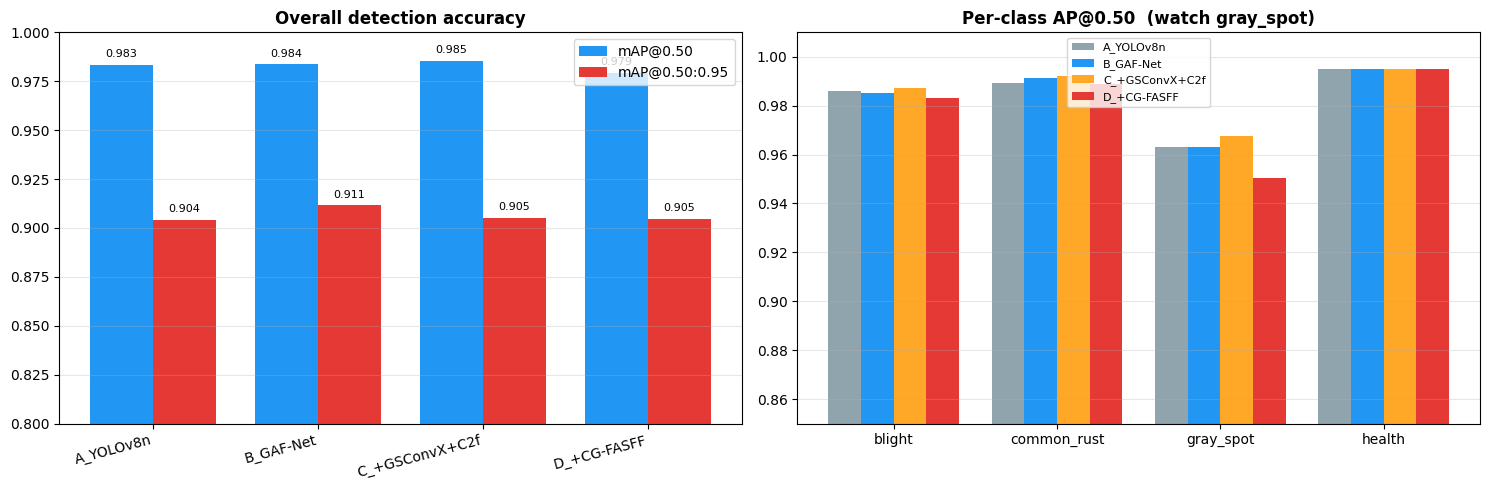

In [10]:
import matplotlib.pyplot as plt
import numpy as np

COLORS = ["#90A4AE", "#2196F3", "#FFA726", "#E53935"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

m = df[["mAP50", "mAP50-95"]]
x = np.arange(len(m)); w = 0.38
axes[0].bar(x - w/2, m["mAP50"],    w, label="mAP@0.50",      color="#2196F3")
axes[0].bar(x + w/2, m["mAP50-95"], w, label="mAP@0.50:0.95", color="#E53935")
axes[0].set_xticks(x); axes[0].set_xticklabels(m.index, rotation=15, ha="right")
axes[0].set_ylim(0.80, 1.0); axes[0].legend(); axes[0].grid(axis="y", alpha=.3)
axes[0].set_title("Overall detection accuracy", fontweight="bold")
for i, (a, b) in enumerate(zip(m["mAP50"], m["mAP50-95"])):
    axes[0].text(i - w/2, a + .004, f"{a:.3f}", ha="center", fontsize=8)
    axes[0].text(i + w/2, b + .004, f"{b:.3f}", ha="center", fontsize=8)

pc = df[[c for c in df.columns if c.startswith("AP50_")]]
pc.columns = [c.replace("AP50_", "") for c in pc.columns]
xs = np.arange(len(pc.columns)); bw = 0.8 / len(pc)
for i, (name, row) in enumerate(pc.iterrows()):
    axes[1].bar(xs + i*bw - 0.4 + bw/2, row.values, bw,
                label=name, color=COLORS[i % len(COLORS)])
axes[1].set_xticks(xs); axes[1].set_xticklabels(pc.columns)
axes[1].set_ylim(0.85, 1.01); axes[1].legend(fontsize=8); axes[1].grid(axis="y", alpha=.3)
axes[1].set_title("Per-class AP@0.50  (watch gray_spot)", fontweight="bold")

plt.tight_layout()
plt.savefig(SAVE_DIR / "plot_ablation.png", dpi=150, bbox_inches="tight")
plt.show()

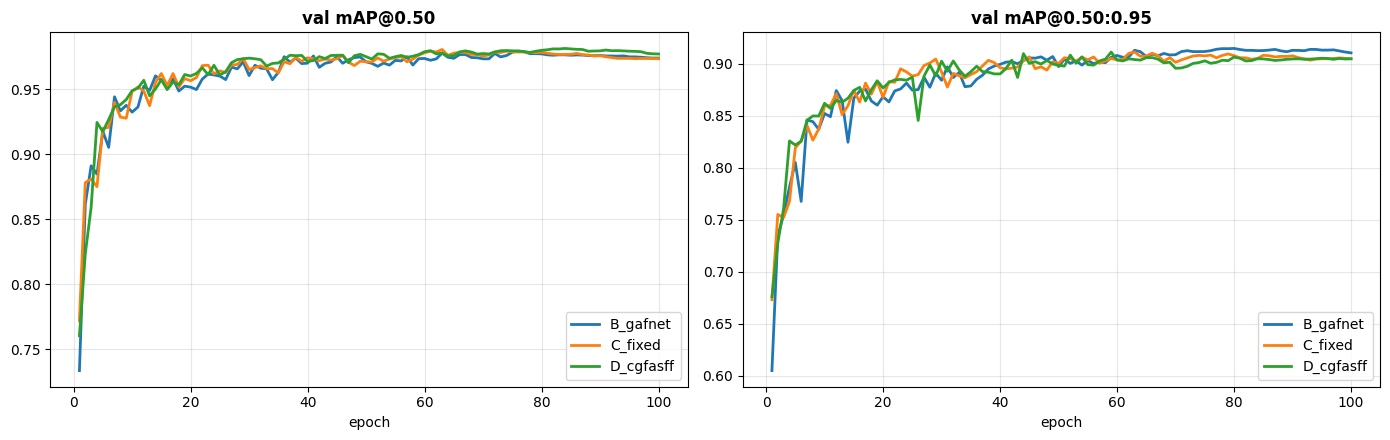

In [11]:
# training curves for the runs trained in THIS notebook
import pandas as pd, matplotlib.pyplot as plt

curves = {t: SAVE_DIR / t / "results.csv"
          for t in ("B_gafnet", "C_fixed", "D_cgfasff")}

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for tag, p in curves.items():
    if not Path(p).exists():
        continue
    d = pd.read_csv(p); d.columns = d.columns.str.strip()
    ax[0].plot(d["epoch"], d["metrics/mAP50(B)"],    lw=2, label=tag)
    ax[1].plot(d["epoch"], d["metrics/mAP50-95(B)"], lw=2, label=tag)
for a, t in zip(ax, ["val mAP@0.50", "val mAP@0.50:0.95"]):
    a.set_xlabel("epoch"); a.set_title(t, fontweight="bold")
    a.legend(); a.grid(alpha=.3)
plt.tight_layout()
plt.savefig(SAVE_DIR / "plot_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 8 — Collect outputs

In [12]:
print("Saved under", SAVE_DIR, "\n")
for f in sorted(SAVE_DIR.rglob("*")):
    if f.is_file():
        print(f"  {f.relative_to(SAVE_DIR)}  ({f.stat().st_size/1024:.0f} KB)")

Saved under /kaggle/working/saved_checkpoints 

  B_gafnet/args.yaml  (2 KB)
  B_gafnet/best.pt  (3999 KB)
  B_gafnet/last.pt  (3999 KB)
  B_gafnet/results.csv  (16 KB)
  C_fixed/args.yaml  (2 KB)
  C_fixed/best.pt  (5576 KB)
  C_fixed/last.pt  (5576 KB)
  C_fixed/results.csv  (16 KB)
  D_cgfasff/args.yaml  (2 KB)
  D_cgfasff/best.pt  (5617 KB)
  D_cgfasff/last.pt  (5617 KB)
  D_cgfasff/results.csv  (16 KB)
  ablation_delta.csv  (0 KB)
  ablation_results.csv  (0 KB)
  plot_ablation.png  (104 KB)
  plot_curves.png  (115 KB)
